In [1]:
import pandas as pd
df = pd.read_csv("Estacoes_SMP.csv")
df.info()
df

ParserError: Error tokenizing data. C error: Expected 1 fields in line 16, saw 3


In [3]:
df.columns

Index(['Número Fistel', 'Número Estação', 'NumCnpjCpf', 'NumServico',
       'Frequência (MHz)', 'Banda_MHZ', 'Frequência Inicial',
       'Frequência Final', 'FreqTxMHz', 'FreqRxMHz', 'Designação Emissão',
       'Número Ato', 'Data Validade', 'Entidade', 'NumSetor', 'Tecnologia',
       'Tipo de Tecnologia 5G', 'Latitude', 'Longitude', 'Latitude decimal',
       'Longitude decimal', 'EnderecoEstacao', 'EndBairro', 'EndNumero',
       'EndComplemento', 'Cep', 'ClassInfraFisica',
       'Data Primeiro Licenciamento', 'Data Licenciamento', 'AnoMesLic',
       'Situacao', 'Caráter', 'Empresa Estação', 'Faixa Estação',
       'Subfaixa Estação', 'Geração', 'Código Nacional', 'Código IBGE',
       'Município-UF', 'UF', 'Nome da UF'],
      dtype='str')

In [4]:
import pandas as pd

colunas_desejadas = [
    'Número Estação', 'Entidade', 'Tecnologia', 
    'Latitude decimal', 'Longitude decimal', 'Município-UF', 'UF'
]

df = pd.read_csv(
    "Estacoes_SMP.csv", 
    sep=";", 
    encoding="utf-8-sig", 
    usecols=colunas_desejadas
)

/tmp/ipykernel_171076/1535902433.py:8: DtypeWarning: Columns (38: Município-UF) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


In [5]:
df

,Número Estação,Entidade,Tecnologia,Latitude decimal,Longitude decimal,Município-UF,UF
0,683532154,TELEFONICA BRASIL S.A.,GSM,-20.142500,-44.898060,Divinópolis - MG,MG
1,689725370,TELEFONICA BRASIL S.A.,LTE,-20.147500,-44.891110,Divinópolis - MG,MG
2,687543665,CLARO S.A.,GSM,-20.177800,-44.898700,Divinópolis - MG,MG
3,665598939,TELEFONICA BRASIL S.A.,LTE,-20.142220,-44.888890,Divinópolis - MG,MG
4,689412746,TIM S A,LTE,-20.147861,-44.863056,Divinópolis - MG,MG
...,...,...,...,...,...,...,...
3331243,1015883602,CLARO S.A.,NR,-9.942210,-67.854220,Rio Branco - AC,AC
3331244,1015666326,CLARO S.A.,LTE,-9.990160,-67.789960,Rio Branco - AC,AC
3331245,695798138,Telefonica Brasil S.a.,LTE,-9.960556,-67.851722,Rio Branco - AC,AC
3331246,441591957,Telefonica Brasil S.a.,NR,-9.969089,-67.821653,Rio Branco - AC,AC


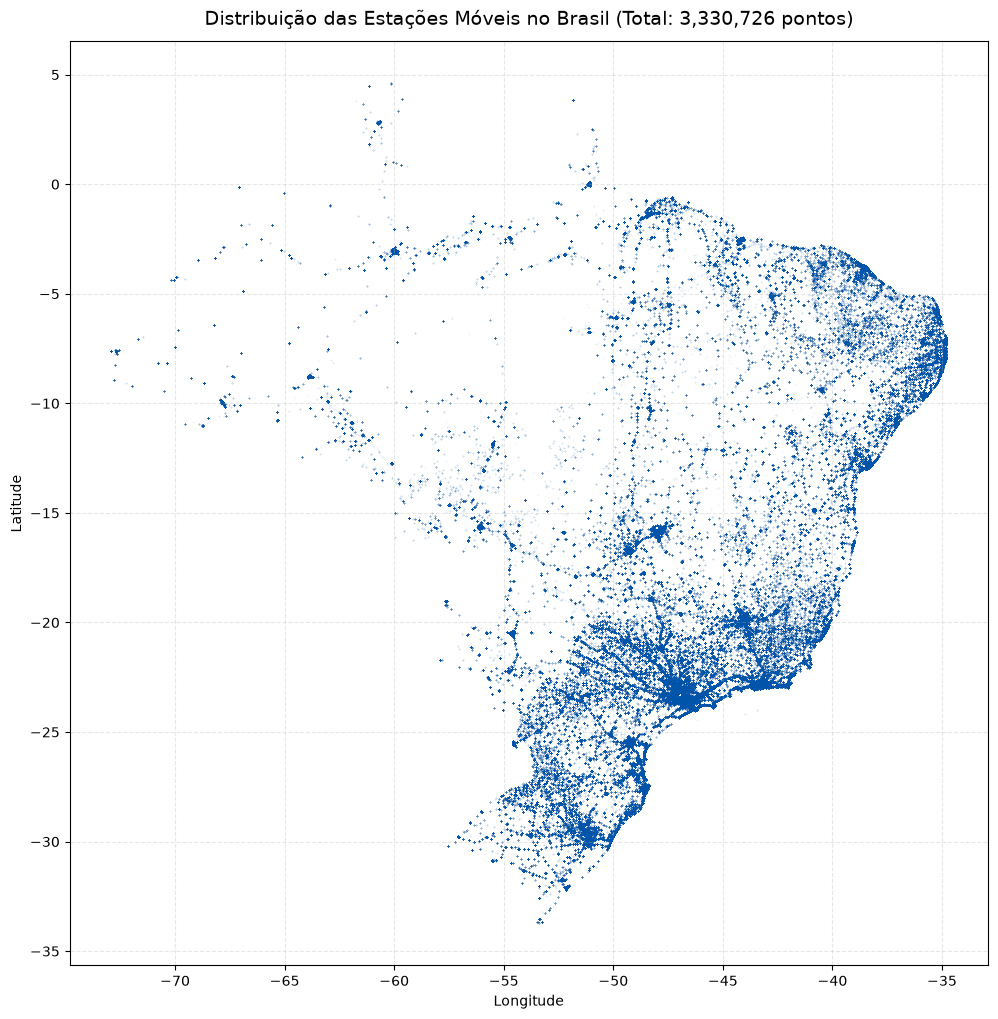

In [6]:
import matplotlib.pyplot as plt

# 1. Filtrar coordenadas válidas dentro dos limites do Brasil
filtro_brasil = (
    (df["Latitude decimal"] <= 6.0) & (df["Latitude decimal"] >= -35.0) &
    (df["Longitude decimal"] <= -34.0) & (df["Longitude decimal"] >= -74.0)
)
df_br = df[filtro_brasil]

# 2. Plotar o mapa de pontos
plt.figure(figsize=(12, 12))

# Como são mais de 3.3 milhões de linhas, usamos pontos pequenos (s=0.1)
# e transparência (alpha=0.03) para destacar a densidade
plt.scatter(
    df_br["Longitude decimal"],
    df_br["Latitude decimal"],
    s=0.1,
    alpha=0.03,
    color="#0055aa",
    rasterized=True
)

plt.title(f"Distribuição das Estações Móveis no Brasil (Total: {len(df_br):,} pontos)", fontsize=14, pad=12)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.gca().set_aspect("equal")  # Proporção correta do mapa
plt.grid(True, linestyle="--", alpha=0.3)

plt.show()


In [9]:
# 1. Quantidade de registros por UF (Estado)
print("=== QUANTIDADE POR UF ===")
print(df["UF"].value_counts())

# 2. Quantidade por Município (Top 25 com mais registros no Brasil)
print("\n=== TOP 25 MUNICÍPIOS NO BRASIL ===")
print(df["Município-UF"].value_counts().head(25))

# 3. (Opcional) Filtrar municípios dentro de um estado específico (ex: Minas Gerais)
print("\n=== TOP 20 MUNICÍPIOS DE MINAS GERAIS ===")
print(df[df["UF"] == "MG"]["Município-UF"].value_counts().head(20))

=== QUANTIDADE POR UF ===
UF
SP    780642
MG    348972
RJ    313812
RS    234651
PR    201561
BA    174066
SC    139893
PE    122022
CE    116109
PA    115968
GO    102240
DF     79899
ES     78105
MA     65742
AM     64398
MT     59532
PB     50358
RN     48018
MS     46593
AL     40656
PI     40461
SE     31107
TO     22611
RO     21672
AP     14406
AC      9816
RR      7938
Name: count, dtype: int64

=== TOP 25 MUNICÍPIOS NO BRASIL ===
Município-UF
São Paulo - SP                76620
Rio de Janeiro - RJ           50099
Brasília - DF                 26633
Belo Horizonte - MG           20648
Manaus - AM                   16501
Salvador - BA                 16158
Curitiba - PR                 15639
Fortaleza - CE                14213
Porto Alegre - RS             13586
Recife - PE                   11356
Belém - PA                    10483
Goiânia - GO                   9554
Campinas - SP                  8076
São Luís - MA                  6623
Campo Grande - MS              6472
Mace